# №5. Масштаб и проективное преобразование

Цель: увеличить и уменьшить изображение в пять раз, затем применить общую матрицу
проективного преобразования. Все вычисления выполняются в NumPy.

In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

In [2]:
plt.rcParams['figure.dpi'] = 110
plt.rcParams['image.cmap'] = 'gray'
plt.rcParams['image.interpolation'] = 'nearest'


def to_uint8(image):
    return np.clip(np.rint(image), 0, 255).astype(np.uint8)


def show_images(images, titles, cols=3, figsize=None):
    rows = (len(images) + cols - 1) // cols
    figsize = figsize or (4 * cols, 3.2 * rows)
    fig, axes = plt.subplots(rows, cols, figsize=figsize, squeeze=False)
    for ax in axes.flat:
        ax.axis('off')
    for ax, image, title in zip(axes.flat, images, titles):
        if image.ndim == 2:
            ax.imshow(image, vmin=0, vmax=255)
        else:
            ax.imshow(to_uint8(image))
        ax.set_title(title)
    fig.tight_layout()
    plt.show()

In [3]:
image = np.array(Image.open("data/geometry.png").convert("RGB"))
print("Исходный размер:", image.shape)

Исходный размер: (300, 300, 3)


In [4]:
def sample_image(image, x, y, method="bilinear", background=0):
    """Значения изображения в вещественных координатах x, y."""
    source = np.asarray(image, dtype=float)
    h, w = source.shape[:2]
    x = np.clip(x, -2, w + 1)
    y = np.clip(y, -2, h + 1)

    def get_pixel(ix, iy):
        valid = (ix >= 0) & (ix < w) & (iy >= 0) & (iy < h)
        values = source[np.clip(iy, 0, h - 1), np.clip(ix, 0, w - 1)]
        if source.ndim == 3:
            valid = valid[..., None]
        return np.where(valid, values, background)

    if method == "nearest":
        return get_pixel(np.floor(x + 0.5).astype(int), np.floor(y + 0.5).astype(int))

    x0, y0 = np.floor(x).astype(int), np.floor(y).astype(int)
    wx, wy = x - x0, y - y0
    if source.ndim == 3:
        wx, wy = wx[..., None], wy[..., None]
    return ((1 - wx) * (1 - wy) * get_pixel(x0, y0)
            + wx * (1 - wy) * get_pixel(x0 + 1, y0)
            + (1 - wx) * wy * get_pixel(x0, y0 + 1)
            + wx * wy * get_pixel(x0 + 1, y0 + 1))

## 1. Увеличение в пять раз

Связываем центры пикселей: $x=(x'+0.5)W/W'-0.5$, $y=(y'+0.5)H/H'-0.5$.
У границы продолжаем крайний пиксель. Сравниваем ближайшего соседа и билинейную интерполяцию.

Увеличенный размер: (1500, 1500, 3)


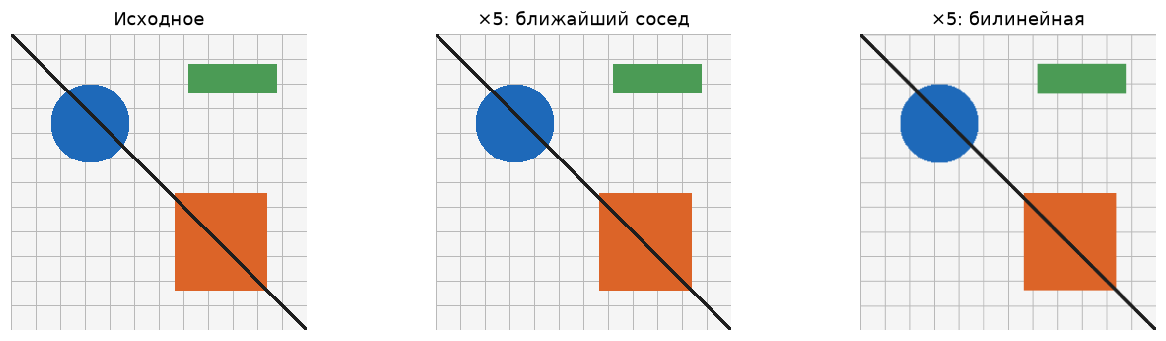

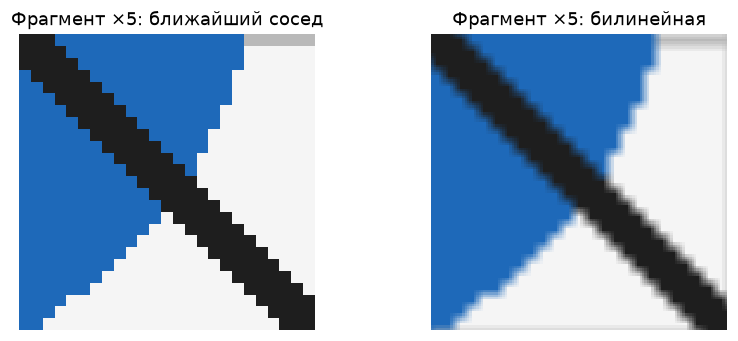

In [5]:
def resize(image, scale, method="bilinear"):
    h, w = image.shape[:2]
    new_h, new_w = round(h * scale), round(w * scale)
    y, x = np.indices((new_h, new_w), dtype=float)
    source_x = np.clip((x + 0.5) * w / new_w - 0.5, 0, w - 1)
    source_y = np.clip((y + 0.5) * h / new_h - 0.5, 0, h - 1)
    return sample_image(image, source_x, source_y, method)

large_nearest = resize(image, 5, "nearest")
large_bilinear = resize(image, 5, "bilinear")
print("Увеличенный размер:", large_bilinear.shape)
show_images([image, to_uint8(large_nearest), to_uint8(large_bilinear)],
            ["Исходное", "×5: ближайший сосед", "×5: билинейная"])

# Одинаковая исходная область после увеличения.
h, w = image.shape[:2]
y0, x0 = h // 3, w // 3
region = np.s_[5*y0:5*(y0+25), 5*x0:5*(x0+25)]
show_images([to_uint8(large_nearest[region]), to_uint8(large_bilinear[region])],
            ["Фрагмент ×5: ближайший сосед", "Фрагмент ×5: билинейная"], cols=2)

## 2. Уменьшение в пять раз

Для усреднения каждый блок $5\times5$ заменяется средним по площади.
В демонстрации отрезаем край до размера, кратного пяти. Все три метода получают один исходный массив.

Размер после уменьшения: (60, 60, 3)


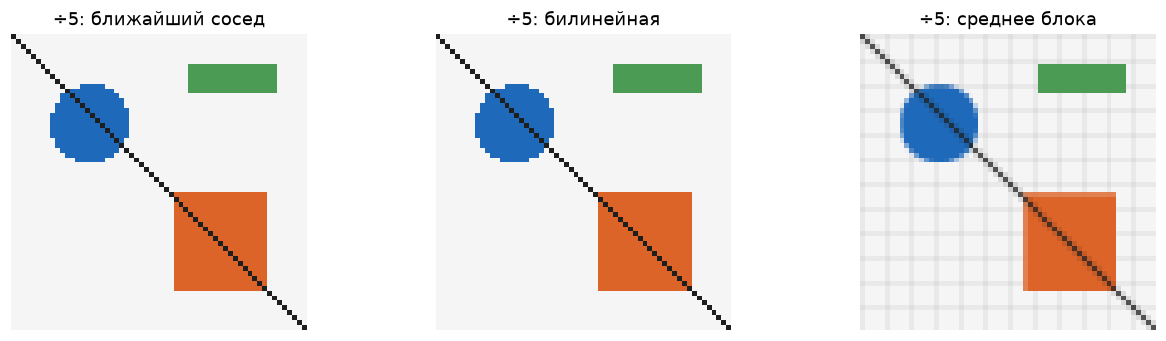

In [6]:
def downsample_average(image, factor=5):
    h, w = image.shape[:2]
    shape = (h // factor, factor, w // factor, factor) + image.shape[2:]
    return np.asarray(image, dtype=float).reshape(shape).mean(axis=(1, 3))

h, w = image.shape[:2]
cropped = image[:h // 5 * 5, :w // 5 * 5]
small_nearest = resize(cropped, 1 / 5, "nearest")
small_bilinear = resize(cropped, 1 / 5, "bilinear")
small_average = downsample_average(cropped)
print("Размер после уменьшения:", small_average.shape)
show_images([to_uint8(small_nearest), to_uint8(small_bilinear), to_uint8(small_average)],
            ["÷5: ближайший сосед", "÷5: билинейная", "÷5: среднее блока"])

### Частая сетка и алиасинг

Шахматное поле из однопиксельных клеток содержит высокие пространственные частоты.
Считаем разброс результата вокруг среднего уровня 127.5.

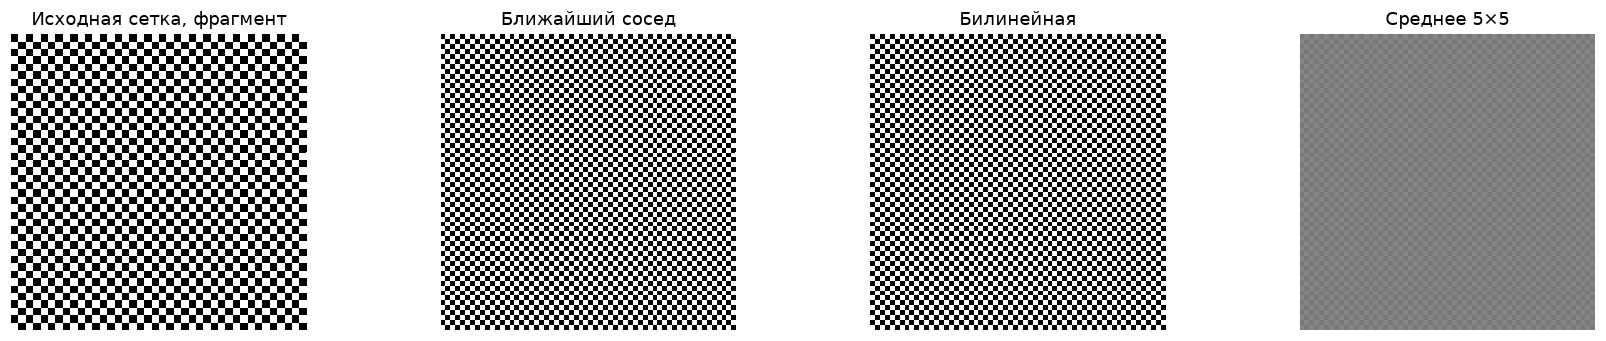

Ближайший сосед     : среднее = 127.50, σ = 127.50
Билинейная          : среднее = 127.50, σ = 127.50
Среднее 5×5         : среднее = 127.50, σ =   5.10


In [7]:
y, x = np.indices((300, 300))
checker = ((x + y) % 2 * 255).astype(np.uint8)
checker_results = [resize(checker, 0.2, "nearest"), resize(checker, 0.2, "bilinear"),
                   downsample_average(checker)]
show_images([checker[:40, :40], *[to_uint8(a) for a in checker_results]],
            ["Исходная сетка, фрагмент", "Ближайший сосед", "Билинейная", "Среднее 5×5"], cols=4)
for name, result in zip(["Ближайший сосед", "Билинейная", "Среднее 5×5"], checker_results):
    print(f"{name:20s}: среднее = {result.mean():6.2f}, σ = {result.std():6.2f}")

## 3. Общая проективная матрица

$$\begin{pmatrix}u\\v\\z\end{pmatrix}=H\begin{pmatrix}x\\y\\1\end{pmatrix},
\qquad x'=u/z,\quad y'=v/z.$$

Для заполнения выходного холста используем $H^{-1}$. Координаты с почти нулевым
однородным знаменателем получают значение фона. Холст задаётся явно.

Матрица H:
 [[ 9.2e-01  2.0e-01  1.5e+01]
 [-8.0e-02  9.8e-01  3.0e+01]
 [ 1.2e-03  5.0e-04  1.0e+00]]


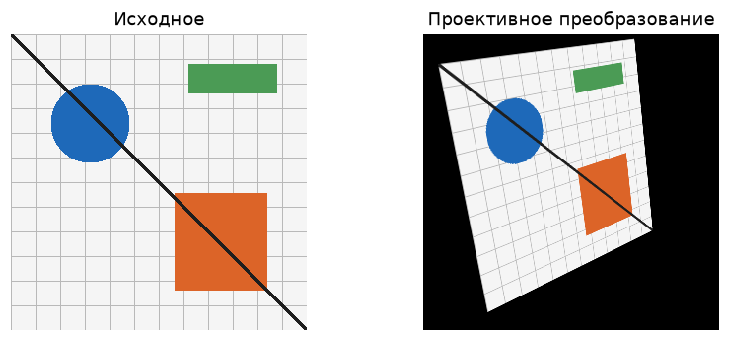

In [8]:
def warp_projective(image, matrix, output_shape=None, method="bilinear", background=0):
    matrix = np.asarray(matrix, dtype=float)
    inverse = np.linalg.inv(matrix)
    # Однородная матрица допускает общий масштаб.
    inverse /= np.max(np.abs(inverse))
    h, w = image.shape[:2] if output_shape is None else output_shape
    y, x = np.indices((h, w), dtype=float)
    points = np.stack([x.ravel(), y.ravel(), np.ones(h * w)])
    source = inverse @ points
    valid = np.abs(source[2]) > 1e-12
    source_x = np.full(h * w, -2.0)
    source_y = np.full(h * w, -2.0)
    np.divide(source[0], source[2], out=source_x, where=valid)
    np.divide(source[1], source[2], out=source_y, where=valid)
    return sample_image(image, source_x.reshape(h, w), source_y.reshape(h, w),
                        method, background)

H = np.array([[0.92, 0.20, 15],
              [-0.08, 0.98, 30],
              [0.0012, 0.0005, 1]])
projected = warp_projective(image, H)
print("Матрица H:\n", H)
show_images([image, to_uint8(projected)], ["Исходное", "Проективное преобразование"], cols=2)

## Вывод

При увеличении ближайший сосед подчёркивает структуру исходных пикселей,
билинейная интерполяция сглаживает границы. При уменьшении в пять раз центры
выходных пикселей попадают в центры исходных; оба точечных метода сохраняют
алиасинг частой сетки. Усреднение по площади подавляет высокие частоты.
Проективная матрица меняет положение, наклон и перспективу плоскости;
деление на однородную координату создаёт перспективное сокращение.